In [1]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../meft_2014-2025.csv")
df['약효분류코드'] = df['약효분류코드'].astype(int).astype(str)


,연도,전체시장_금액,999제외_금액,전체시장_성장률(%),999제외_성장률(%)
0,2014,14998302.0,14998182.0,NaN,NaN
1,2015,15767159.0,15631643.0,5.13,4.22
2,2016,17362169.0,17357709.0,10.12,11.04
3,2017,18398390.0,18398155.0,5.97,5.99
4,2018,19976763.0,19976024.0,8.58,8.58
5,2019,21691150.0,21688027.0,8.58,8.57
6,2020,22447916.0,22427978.0,3.49,3.41
7,2021,24286854.0,24271542.0,8.19,8.22
8,2022,26580771.0,26562461.0,9.45,9.44
9,2023,28755071.0,28735990.0,8.18,8.18


findfont: Failed to find font weight bold for NanumGothic, now using 600.


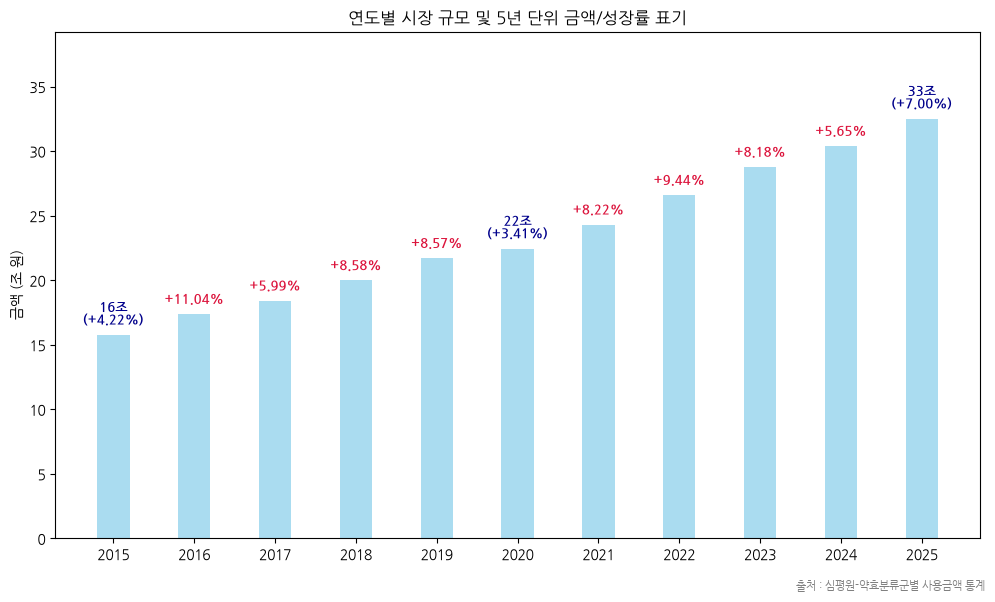

In [3]:
df_all = df.groupby('연도')['사용금액_백만원'].sum().reset_index(name='전체시장_금액')
df_except_999 = df[df['약효분류코드'] != '999'].groupby('연도')['사용금액_백만원'].sum().reset_index(name='999제외_금액')

# 4. 데이터 병합 (병렬로 비교하기 위함)
market_trend = pd.merge(df_all, df_except_999, on='연도')

# 5. 연도별 성장률(YoY, 전년 대비 성장률) 계산
market_trend['전체시장_성장률(%)'] = market_trend['전체시장_금액'].pct_change() * 100
market_trend['999제외_성장률(%)'] = market_trend['999제외_금액'].pct_change() * 100

# 보기 좋게 소수점 둘째 자리로 반올림
market_trend = market_trend.round(2)
display(market_trend)

plt.rc('font', family='NanumGothic')
plt.rcParams['axes.unicode_minus'] = False # 마이너스 기호 깨짐 방지

# 1. 도화지 생성
fig, ax = plt.subplots(figsize=(10, 6))

# 2. 데이터 준비 (2014년 제외)
df_plot = market_trend[1:].copy()
x = df_plot['연도'].astype(str)
y_amount = df_plot['전체시장_금액'] / 1e6
y_rate = df_plot['전체시장_성장률(%)']

# 3. 막대 그래프 그리기
bars = ax.bar(x, y_amount, color='skyblue', alpha=0.7, width=0.4, label='전체시장_금액')
ax.set_ylabel('금액 (조 원)')
ax.set_title('연도별 시장 규모 및 5년 단위 금액/성장률 표기')

# 4. 텍스트 표기 로직 (5의 배수 연도인 경우 금액 + 성장률 함께 표시)
for bar, row in zip(bars, df_plot.itertuples()):
    year = int(row.연도)
    rate = row._5  # 999제외_성장률(%) 컬럼 인덱스에 따라 확인 필요 (또는 row.연도, row.전체시장_금액 등 활용)
    amount = bar.get_height()
    height = amount
    
    # 5의 배수 연도 판별 (예: 2015, 2020, 2025...)
    if year % 5 == 0:
        # 금액과 성장률을 함께 표시
        text_label = f"{amount:,.0f}조\n({rate:+.2f}%)"
        text_color = 'darkblue'
    else:
        # 일반 연도는 성장률만 표시
        text_label = f"{rate:+.2f}%"
        text_color = 'crimson'
        
    ax.text(
        bar.get_x() + bar.get_width() / 2.,
        height + (ax.get_ylim()[1] * 0.02),
        text_label,
        ha='center', 
        va='bottom', 
        fontsize=9, 
        color=text_color, 
        weight='bold'
    )

# 여유 공간 확보
ax.set_ylim(0, ax.get_ylim()[1] * 1.15)
fig.tight_layout(rect=[0, 0.03, 1, 1])

# 5. 그래프 하단 우측에 출처 표기 추가
plt.figtext(0.99, 0.01, "출처 : 심평원-약효분류군별 사용금액 통계", horizontalalignment='right', fontsize=8, color='gray')
plt.show()

In [92]:

df['연도'] = df['연도'].astype(int)

# 2. 2022~2025년 데이터 필터링 및 약효분류코드별 연도별 사용금액 합계 집계
target_years = [2022, 2023, 2024, 2025]
df_filtered = df[df['연도'].isin(target_years)]

# 피벗 테이블 생성 (행: 약효분류코드 및 약효분류명, 열: 연도, 값: 사용금액_백만원 합계)
pivot_df = df_filtered.pivot_table(
    index=['약효분류코드', '약효분류명'],
    columns='연도',
    values='사용금액_백만원',
    aggfunc='sum'
).reset_index()

# 컬럼명 단순화 (MultiIndex 해제)
pivot_df.columns.name = None

# 3. 2023~2024년 중 하나라도 사용금액이 3,000백만 원(30억 원) 이상인 항목 필터링
# (요청하신 조건에 따라 각 해마다 또는 기간 내 기준 충족 여부 확인)
YOY_BASE = 3000
mask = (
    (pivot_df.get(2022, 0) >= YOY_BASE) | 
    (pivot_df.get(2023, 0) >= YOY_BASE) | 
    (pivot_df.get(2024, 0) >= YOY_BASE)
)
filtered_market = pivot_df[mask].copy()


# 4. YoY 계산 (퍼센트: %)

def safe_yoy(curr, prev, threshold=YOY_BASE):
    return np.where(
        prev > threshold,          # 기준연도가 임계값 초과일 때만 계산
        (curr - prev) / prev * 100,
        np.nan # 0으로 하면 연계지표 오류쌓임! (ex . 초과성장률 계산)
    )

filtered_market['YoY_2023(%)'] = safe_yoy(filtered_market[2023], filtered_market[2022])
filtered_market['YoY_2024(%)'] = safe_yoy(filtered_market[2024], filtered_market[2023])
filtered_market['YoY_2025(%)'] = safe_yoy(filtered_market[2025], filtered_market[2024])


# 보기 좋게 컬럼 순서 재배치 및 소수점 반올림
filtered_table = filtered_market[['약효분류코드', '약효분류명', 2022, 2023, 2024, 2025, 'YoY_2023(%)', 'YoY_2024(%)', 'YoY_2025(%)']].copy()
filtered_table.columns = ['약효분류코드', '약효분류명', '2022년_금액', '2023년_금액', '2024년_금액', '2025년_금액', 'YoY(23/22_%)', 'YoY(24/23_%)', 'YoY(25/24_%)']
filtered_table = filtered_table.round(2)

# 금액 기준으로 내림차순 정렬
filtered_table = filtered_table.sort_values(by='2025년_금액', ascending=False).reset_index(drop=True)

# 5. 결과 출력
print(f"=== 2022~2024년 사용금액 {int(YOY_BASE/100)}억 이상 약효분류코드별 성장 추이 (총 {len(filtered_table)}개) ===")
filtered_table.head()

=== 2022~2024년 사용금액 30억 이상 약효분류코드별 성장 추이 (총 96개) ===


,약효분류코드,약효분류명,2022년_금액,2023년_금액,2024년_금액,2025년_금액,YoY(23/22_%),YoY(24/23_%),YoY(25/24_%)
0,421,항악성종양제,2562332.0,2870046.0,3313853.0,3794734.0,12.01,15.46,14.51
1,218,동맥경화용제,2805454.0,3086470.0,3357567.0,3610176.0,10.02,8.78,7.52
2,214,혈압강하제,2102984.0,2160703.0,2206636.0,2266758.0,2.74,2.13,2.72
3,232,소화성궤양용제,1466295.0,1561910.0,1634300.0,1725405.0,6.52,4.63,5.57
4,396,당뇨병용제,1426472.0,1488244.0,1533432.0,1588043.0,4.33,3.04,3.56


In [93]:
consecutive_growth_df = filtered_table[(filtered_table['YoY(25/24_%)']>0)&(filtered_table['YoY(24/23_%)']>0)]
consecutive_growth_df.shape

(59, 9)

In [95]:
# 2. 시장 전체 연도별(2022~2025) 사용금액 합계 계산 (999 제외 기준 또는 전체 기준 중 선택, 여기서는 999 제외 기준 적용)
market_yearly = df[df['약효분류코드'] != '999'].groupby('연도')['사용금액_백만원'].sum()

# 시장 전체 YoY (%) 계산
m_yoy_2322 = ((market_yearly[2023] - market_yearly[2022]) / market_yearly[2022]) * 100
m_yoy_2423 = ((market_yearly[2024] - market_yearly[2023]) / market_yearly[2023]) * 100
m_yoy_2524 = ((market_yearly[2025] - market_yearly[2024]) / market_yearly[2024]) * 100

# 시장 전체 성장액 (백만 원) 계산
m_diff_2322 = market_yearly[2023] - market_yearly[2022]
m_diff_2423 = market_yearly[2024] - market_yearly[2023]
m_diff_2524 = market_yearly[2025] - market_yearly[2024]

print(f"[시장 전체(999제외) 성장 지표]")
print(f" - YoY (%): 23/22={m_yoy_2322:.2f}%, 24/23={m_yoy_2423:.2f}%, 25/24={m_yoy_2524:.2f}%")
print(f" - 성장액(백만): 23/22=+{m_diff_2322:,.1f}, 24/23=+{m_diff_2423:,.1f}, 25/24=+{m_diff_2524:,.1f}\n")

# # 3. 개별 약효분류코드별 피벗 테이블 생성 (2022~2025)

# pivot_df = df[df['약효분류코드'] != '999'].pivot_table(
#     index=['약효분류코드', '약효분류명'],
#     columns='연도',
#     values='사용금액_백만원',
#     aggfunc='sum'
# ).reset_index()
# pivot_df.columns.name = None

# # 4. 개별 약효분류군 YoY 및 성장액 계산
# # YoY (%)
# pivot_df['YoY(23/22_%)'] = ((pivot_df[2023] - pivot_df[2022]) / pivot_df[2022]) * 100
# pivot_df['YoY(24/23_%)'] = ((pivot_df[2024] - pivot_df[2023]) / pivot_df[2023]) * 100
# pivot_df['YoY(25/24_%)'] = ((pivot_df[2025] - pivot_df[2024]) / pivot_df[2024]) * 100

# 초과성장률 = 시장 전체 YoY와의 차이 (Diff = 개별 YoY - 시장 전체 YoY) [%p]
consecutive_growth_df['Diff_23/22 (%p)'] = consecutive_growth_df['YoY(23/22_%)'] - m_yoy_2322
consecutive_growth_df['Diff_24/23 (%p)'] = consecutive_growth_df['YoY(24/23_%)'] - m_yoy_2423
consecutive_growth_df['Diff_25/24 (%p)'] = consecutive_growth_df['YoY(25/24_%)'] - m_yoy_2524

# 연도별 성장액 (개별 연도 금액 차이)
consecutive_growth_df['Growth_23/22'] = consecutive_growth_df['2023년_금액'] - consecutive_growth_df['2022년_금액']
consecutive_growth_df['Growth_24/23'] = consecutive_growth_df['2024년_금액'] - consecutive_growth_df['2023년_금액']
consecutive_growth_df['Growth_25/24'] = consecutive_growth_df['2025년_금액'] - consecutive_growth_df['2024년_금액']

# 성장기여도 = 시장 전체 성장액 대비 차지하는 비중 (%) = (개별 성장액 / 시장 전체 성장액) * 100
consecutive_growth_df['Share_Growth_23/22 (%)'] = (consecutive_growth_df['Growth_23/22'] / m_diff_2322) * 100
consecutive_growth_df['Share_Growth_24/23 (%)'] = (consecutive_growth_df['Growth_24/23'] / m_diff_2423) * 100
consecutive_growth_df['Share_Growth_25/24 (%)'] = (consecutive_growth_df['Growth_25/24'] / m_diff_2524) * 100

# 5. 보기 좋은 형태로 컬럼 정리 및 2025년 금액 기준 정렬 후 출력
filtered_analysis = consecutive_growth_df[[
    '약효분류코드', '약효분류명', 
    'YoY(25/24_%)', 'Diff_25/24 (%p)', 'Share_Growth_25/24 (%)',
    'YoY(24/23_%)', 'Diff_24/23 (%p)', 'Share_Growth_24/23 (%)',
    'YoY(23/22_%)', 'Diff_23/22 (%p)', 'Share_Growth_23/22 (%)'
]].copy().round(2)

filtered_analysis = filtered_analysis.sort_values(by='YoY(25/24_%)', ascending=False).reset_index(drop=True)


print("=== 개별 약효분류군 vs 시장 전체 비교 분석 결과 ===")
filtered_analysis = filtered_analysis[filtered_analysis['약효분류코드'].isin(filtered_table['약효분류코드'].unique())]
# filtered_analysis.dtypes, filtered_table.dtypes
filtered_analysis.shape

[시장 전체(999제외) 성장 지표]
 - YoY (%): 23/22=8.18%, 24/23=5.65%, 25/24=7.00%
 - 성장액(백만): 23/22=+2,173,529.0, 24/23=+1,622,205.0, 25/24=+2,124,096.0

=== 개별 약효분류군 vs 시장 전체 비교 분석 결과 ===


(59, 11)

In [96]:
filtered_analysis

,약효분류코드,약효분류명,YoY(25/24_%),Diff_25/24 (%p),Share_Growth_25/24 (%),YoY(24/23_%),Diff_24/23 (%p),Share_Growth_24/23 (%),YoY(23/22_%),Diff_23/22 (%p),Share_Growth_23/22 (%)
0,629,기타의 화학요법제,87.59,80.59,32.38,0.34,-5.31,0.16,6.40,-1.78,2.16
1,429,기타의 종양치료제,26.95,19.95,0.51,241.72,236.07,1.76,4.30,-3.88,0.02
2,235,"최토제,진토제",18.65,11.65,0.92,13.83,8.18,0.79,8.59,0.41,0.34
3,612,주로 그람음성균에 작용하는 것,18.18,11.18,0.24,28.58,22.93,0.38,13.74,5.56,0.12
4,634,혈액제제류,16.81,9.81,2.33,3.98,-1.67,0.69,0.64,-7.54,0.08
5,999,해당사항없음,15.70,8.70,0.14,0.42,-5.23,0.00,4.21,-3.97,0.04
6,249,기타의 호르몬제(항호르몬제를 포함),15.62,8.62,1.85,17.34,11.69,2.29,2.22,-5.96,0.21
7,421,항악성종양제,14.51,7.51,22.64,15.46,9.81,27.36,12.01,3.83,14.16
8,322,무기질제제,11.64,4.64,0.23,23.39,17.74,0.50,8.38,0.20,0.12
9,632,독소류 및 톡소이드류,10.91,3.91,0.02,8.25,2.60,0.02,14.07,5.89,0.02


In [97]:
def get_top_contributor(period='25/24', pct_cut=50):
    # 1. 2025년 성장 기여도 기준 내림차순 정렬
    df_sorted = filtered_analysis.sort_values(by=f'Share_Growth_{period} (%)', ascending=False).reset_index(drop=True)

    # 2. 기여도 누적 합계(Cumulative Sum) 계산
    df_sorted['누적기여도(%)'] = df_sorted[f'Share_Growth_{period} (%)'].cumsum()

    # 3. 누적 기여도가 50%를 최초로 넘어서는 지점(Index)을 찾아 그 행까지만 안전하게 잘라내기
    over_cut_idx = df_sorted[df_sorted['누적기여도(%)'] >= pct_cut].index

    if len(over_cut_idx) > 0:
        cutoff = over_cut_idx[0] + 1  # 50%를 넘은 첫 번째 행까지 포함
        result_top = df_sorted.head(cutoff)
    else:
        result_top = df_sorted

    # 4. 결과 출력용 컬럼 선택 및 정리
    final_display = result_top[[
        '약효분류코드', '약효분류명', 
        f'YoY({period}_%)', f'Diff_{period} (%p)', 
        f'Share_Growth_{period} (%)', '누적기여도(%)'
    ]].copy()

    print(f"=== 20{period[:2]}년 시장 전체 성장의 {pct_cut}% 이상을 견인한 상위 약효분류군 (총 {len(final_display)}개) ===")
    display(final_display)

    return final_display

=== 2025년 시장 전체 성장의 80% 이상을 견인한 상위 약효분류군 (총 7개) ===


,약효분류코드,약효분류명,YoY(25/24_%),Diff_25/24 (%p),Share_Growth_25/24 (%),누적기여도(%)
0,629,기타의 화학요법제,87.59,80.59,32.38,32.38
1,421,항악성종양제,14.51,7.51,22.64,55.02
2,218,동맥경화용제,7.52,0.52,11.89,66.91
3,232,소화성궤양용제,5.57,-1.43,4.29,71.20
4,219,기타의 순환계용약,10.40,3.40,4.19,75.39
5,142,자격료법제(비특이성면역원제제를 포함),8.32,1.32,3.40,78.79
6,131,안과용제,7.29,0.29,3.29,82.08


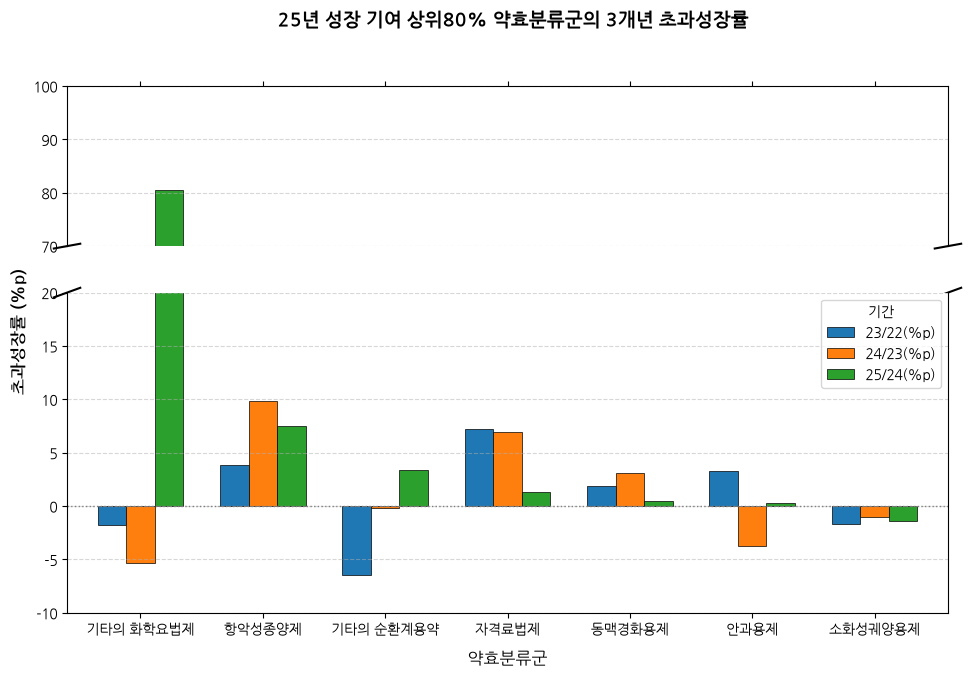

In [98]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# 1. 데이터 추출 및 가공
PCT_CUT = 80
top75_codes = get_top_contributor('25/24', PCT_CUT).약효분류코드.unique()

excess_plot_df = (
    filtered_analysis[filtered_analysis.약효분류코드.isin(top75_codes)]
    .set_index('약효분류명')[
        ['Diff_23/22 (%p)', 'Diff_24/23 (%p)', 'Diff_25/24 (%p)']
    ]
)
excess_plot_df.index = excess_plot_df.index.str.replace(r"\s*\(.*?\)", "", regex=True)

excess_plot_df.columns = ['23/22(%p)', '24/23(%p)', '25/24(%p)']

# 2. 상단과 하단 서브플롯 생성 (Y축 30~70 구간 분할)
# fig 크기를 키우고(11x7) 좌측 여백을 확보하기 위해 left 조정
fig, (ax1, ax2) = plt.subplots(
    2, 1, sharex=True, figsize=(11, 7), gridspec_kw={'height_ratios': [1, 2]}
)
fig.subplots_adjust(
    hspace=0.08, left=0.15
)  # 💡 left=0.15를 주어 Y축 레이블 공간 확보

# 3. 양쪽 서브플롯에 동일하게 그룹형 막대 그래프 그리기
excess_plot_df.plot(
    kind='bar', ax=ax1, width=0.7, edgecolor='black', linewidth=0.5, legend=False
)
excess_plot_df.plot(
    kind='bar', ax=ax2, width=0.7, edgecolor='black', linewidth=0.5
)

# 4. Y축 범위 설정 (30~70 구간 생략)
ax1.set_ylim(70, 100)
ax2.set_ylim(-10, 20)

# 5. 불필요한 테두리 및 축 눈금 정리
ax1.spines['bottom'].set_visible(False)
ax2.spines['top'].set_visible(False)
ax1.xaxis.tick_top()
ax1.tick_params(labeltop=False)
ax2.xaxis.tick_bottom()

# 6. 절단선(물결 표시 대용 사선) 추가
d = 0.015
kwargs = dict(
    transform=ax1.transAxes, color='k', clip_on=False, linewidth=1.5
)
ax1.plot((-d, +d), (-d, +d), **kwargs)
ax1.plot((1 - d, 1 + d), (-d, +d), **kwargs)

kwargs.update(transform=ax2.transAxes)
ax1.plot((-d, +d), (1 - d, 1 + d), **kwargs)
ax1.plot((1 - d, 1 + d), (1 - d, 1 + d), **kwargs)

# 7. 디자인, 라벨 및 범례 설정
ax2.set_xlabel('약효분류군', fontsize=12, labelpad=10)

# 💡 Y축 레이블이 숫자와 겹치지 않도록 좌표(x=-0.12)를 더 왼쪽으로 이동
fig.text(
    0.05,
    0.5,
    '초과성장률 (%p)',
    va='center',
    ha='center',
    rotation='vertical',
    fontsize=12,
    weight='bold',
)

plt.xticks(rotation=0, fontsize=10)

ax1.grid(axis='y', linestyle='--', alpha=0.5)
ax2.grid(axis='y', linestyle='--', alpha=0.5)
ax2.axhline(0, color='gray', linestyle=':', linewidth=1)

plt.suptitle(
    f'25년 성장 기여 상위{PCT_CUT}% 약효분류군의 3개년 초과성장률',
    fontsize=14,
    weight='bold',
    x=0.5,
    y=0.96,
)

# 범례가 그래프와 겹치지 않게 우측 바깥쪽 위치 조정
ax2.legend(
    title='기간',
    fontsize=10,
    # bbox_to_anchor=(1.02, 1),
    loc='upper right',
    frameon=True,
)

# 여백을 침범하지 않도록 조정 (rect로 전체 영역 관리)
plt.tight_layout(rect=[0.05, 0, 0.92, 0.93])
plt.show()

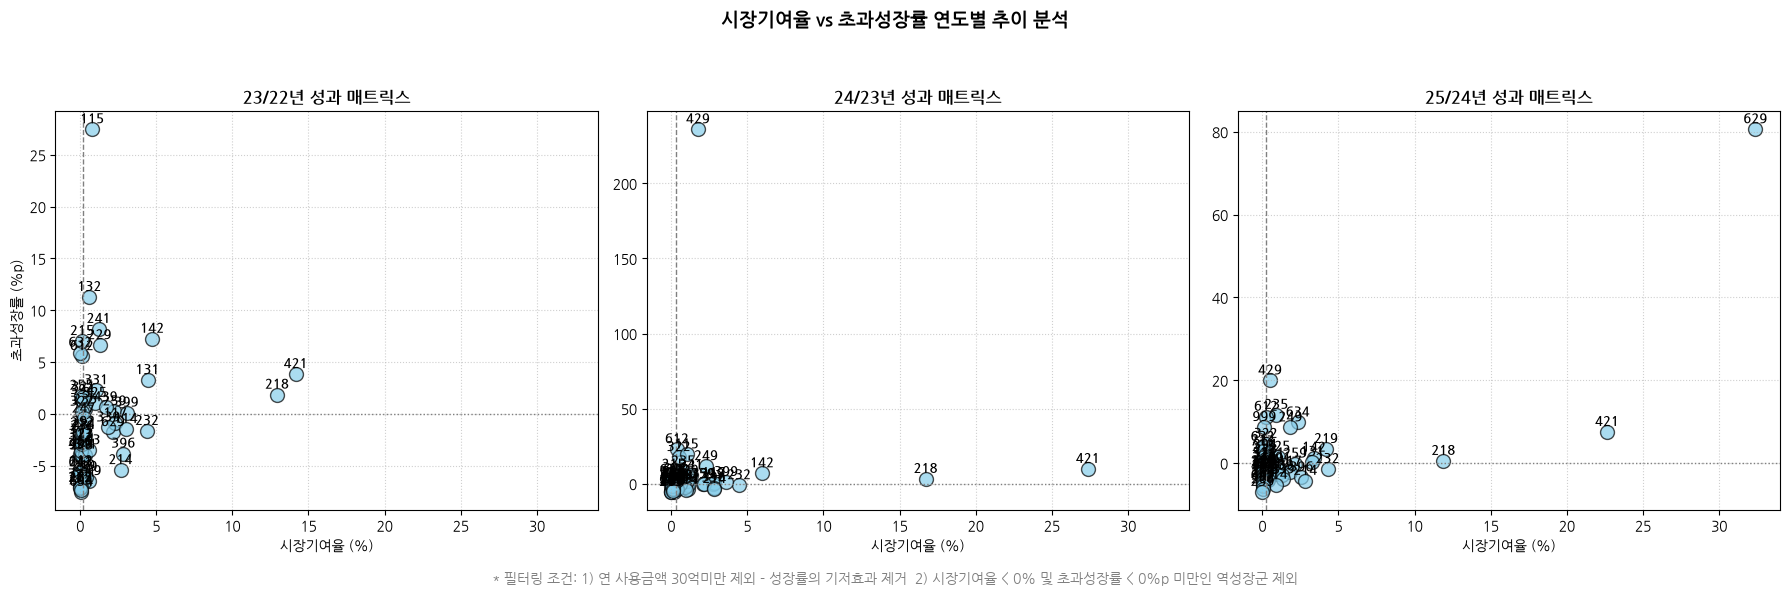

In [104]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. 'diff'와 'share' 컬럼 자동 추출
diff_cols = [
    c for c in filtered_analysis.columns if c.lower().startswith('diff')
]
share_cols = [
    c for c in filtered_analysis.columns if c.lower().startswith('share')
]

# 2. 💡 데이터프레임 전체 단계에서 두 가지 필터링 조건 동시 적용
# 조건 A: 초과성장률(diff) 중 하나라도 1000을 초과하면 제거
# 조건 B: 3개년 중 어느 한 해라도 '시장기여율 < 0 이고 초과성장률 < 0'인 경우 데이터프레임에서 제외
# (필요에 따라 조건 B를 연도별 개별 적용으로 바꾸려면 아래 주석을 참고하세요)

valid_mask = (filtered_analysis[diff_cols] <= 1000).all(axis=1)

for yr in ['23/22', '24/23', '25/24']:
  s_col = [
      c for c in filtered_analysis.columns if c.lower().startswith('share') and yr in c
  ][0]
  d_col = [
      c for c in filtered_analysis.columns if c.lower().startswith('diff') and yr in c
  ][0]
  # 특정 연도 기준 저성과군 제거를 원할 경우 아래 마스크 활용 가능
  valid_mask &= ~((filtered_analysis[s_col] < 0) & (filtered_analysis[d_col] < 0))

clean_df = filtered_analysis[valid_mask].copy()

# 3. 연도별 패싯 스캐터 플롯 시각화
years = ['23/22', '24/23', '25/24']
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=False)

for i, yr in enumerate(years):
  ax = axes[i]

  share_col = [
      c for c in clean_df.columns if c.lower().startswith('share') and yr in c
  ][0]
  diff_col = [
      c for c in clean_df.columns if c.lower().startswith('diff') and yr in c
  ][0]

  x_vals = clean_df[share_col]
  y_vals = clean_df[diff_col]

  # 스캐터 플롯 그리기
  ax.scatter(
      x_vals,
      y_vals,
      alpha=0.7,
      s=100,
      edgecolors='black',
      c='skyblue',
      linewidth=1,
  )

  # 사분면 기준선 (중앙값 및 0 기준)
  ax.axvline(
      x_vals.median() if not x_vals.empty else 0,
      color='gray',
      linestyle='--',
      linewidth=1,
  )
  ax.axhline(0, color='gray', linestyle=':', linewidth=1)

  # 약효분류코드 레이블 표시
  for idx, row in clean_df.iterrows():
    ax.annotate(
        str(row['약효분류코드']),
        (row[share_col], row[diff_col]),
        xytext=(0, 5),
        textcoords='offset points',
        ha='center',
        fontsize=9,
        weight='bold',
    )

  ax.set_title(f'{yr}년 성과 매트릭스', fontsize=12, weight='bold')
  ax.set_xlabel('시장기여율 (%)', fontsize=10)
  if i == 0:
    ax.set_ylabel('초과성장률 (%p)', fontsize=10)
  ax.grid(True, linestyle=':', alpha=0.6)

# 제목 설정 (필터링 조건 미포함)
plt.suptitle(
    '시장기여율 vs 초과성장률 연도별 추이 분석',
    fontsize=14,
    weight='bold',
    y=0.98,
)

# 💡 필터링 조건을 그래프 하단에 회색(gray) 텍스트로 배치
filter_desc = (
    '* 필터링 조건: 1) 연 사용금액 30억미만 제외 - 성장률의 기저효과 제거  2) 시장기여율 < 0% 및 초과성장률 < 0%p 미만인 역성장군 제외'
)
fig.text(
    0.5,
    0.02,
    filter_desc,
    ha='center',
    va='bottom',
    fontsize=10,
    color='gray',
    style='italic',
)

plt.tight_layout(rect=[0, 0.05, 1, 0.93])  # 하단 텍스트 공간 확보
plt.show()

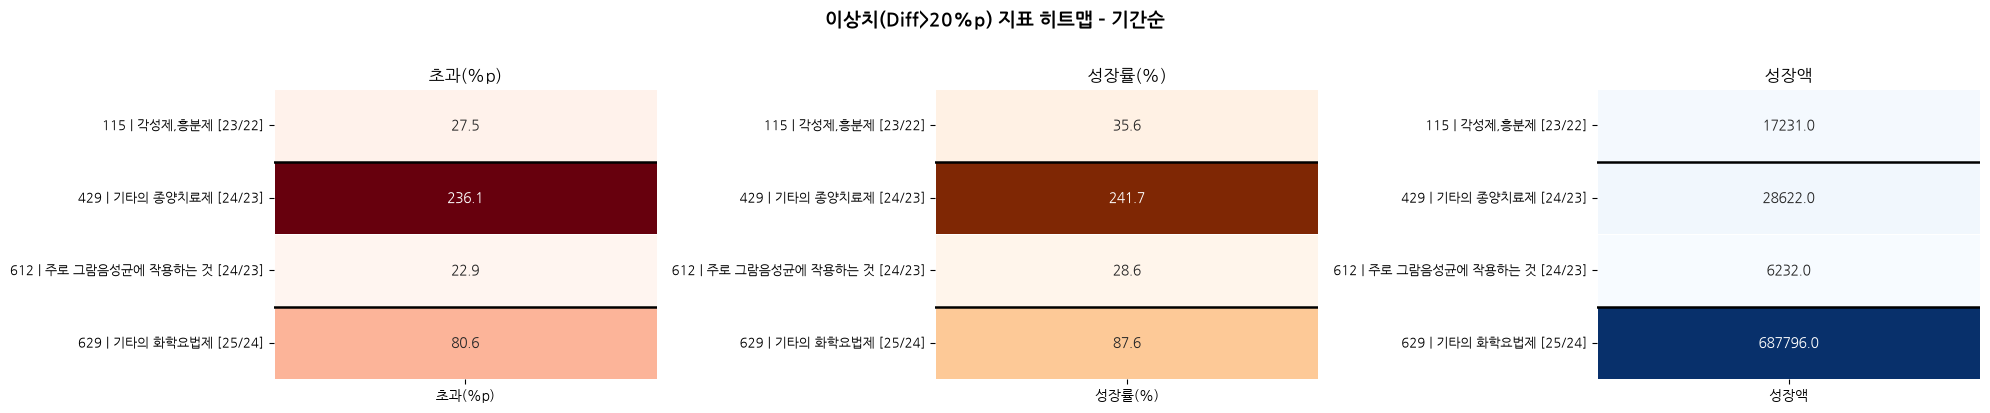

In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns

# 이상치 조건별 컬럼 매핑 (기간: (Diff컬럼, YoY컬럼, Growth컬럼))
PERIODS = {
    '23/22': ('Diff_23/22 (%p)', 'YoY(23/22_%)', 'Growth_23/22'),
    '24/23': ('Diff_24/23 (%p)', 'YoY(24/23_%)', 'Growth_24/23'),
    '25/24': ('Diff_25/24 (%p)', 'YoY(25/24_%)', 'Growth_25/24'),
}

# 각 기간별 이상치 코드 집합 (초과성장률 > 20% )
outliers = {p: set(consecutive_growth_df.loc[consecutive_growth_df[d] > 20, '약효분류코드'])
            for p, (d, _, _) in PERIODS.items()}

# long format (comprehension 한 방)
# 1) long 생성
long = pd.DataFrame([
    {'코드': r['약효분류코드'], '명': r['약효분류명'], '기간': p,
     '초과(%p)': r[d], '성장률(%)': r[y], '성장액': r[g]}
    for _, r in consecutive_growth_df.iterrows()
    for p, (d, y, g) in PERIODS.items()
    if r['약효분류코드'] in outliers[p]
])
long['라벨'] = long['코드'].astype(str) + ' | ' + long['명'] + ' [' + long['기간'] + ']'

# 1) 정렬
long['기간'] = pd.Categorical(long['기간'], categories=['23/22','24/23','25/24'], ordered=True)
long_sorted = (long.sort_values(['기간','초과(%p)'], ascending=[True, False])
                   .set_index('라벨'))

# 2) 경계 계산
sizes = long_sorted.reset_index().groupby('기간', observed=True).size()
boundaries = sizes.cumsum().values[:-1]      # [23|24 경계, 24|25 경계]

# 3) 히트맵
metrics, cmaps = ['초과(%p)','성장률(%)','성장액'], ['Reds','Oranges','Blues']
fig, axes = plt.subplots(1, 3, figsize=(20, max(4, len(long_sorted)*0.32)))

for ax, m, c in zip(axes, metrics, cmaps):
    sns.heatmap(long_sorted[[m]], annot=True, fmt='.1f',
                cmap=c, linewidths=.5, ax=ax, cbar=False, yticklabels=True)
    ax.set_title(m); ax.set_xlabel(''); ax.set_ylabel('')
    ax.tick_params(axis='y', labelsize=9)
    # ✅ 기간 경계선
    for b in boundaries:
        ax.axhline(b, color='black', lw=1.8, zorder=5)

plt.suptitle('이상치(Diff>20%p) 지표 히트맵 – 기간순',    fontsize=14, weight='bold', y=1.02)

plt.tight_layout(); plt.show()

In [101]:
outliers

{'23/22': {'115'}, '24/23': {'429', '612'}, '25/24': {'629'}}

In [112]:
import pandas as pd

# ---------------------------------------------------------
# 조건 1: 2025년 기준 성장기여율이 매우 낮지만(<10%), 3개년 연속 초과성장률이 5%p넘는 것
# ---------------------------------------------------------
group1 = filtered_analysis[
    (filtered_analysis['Share_Growth_25/24 (%)'] < 10)
    & (filtered_analysis['Share_Growth_25/24 (%)'] >= 0)  # 필요시 음수 포함 여부 확인
    & (filtered_analysis['Diff_25/24 (%p)'] > 5) # 25/24년 초과성장 > 0
    & (filtered_analysis['Diff_24/23 (%p)'] > 5)  # 24/23년 초과성장 > 0
    
]

print('=== [조건 1] 저기여(<10%) + 연속 초과 고성장(>5%p) ===')
display(
    group1[['약효분류코드', '약효분류명', 'Share_Growth_25/24 (%)', 'Diff_25/24 (%p)', 'Diff_24/23 (%p)','YoY(25/24_%)','YoY(24/23_%)']]
    if not group1.empty
    else '조건에 해당하는 항목이 없습니다.'
)
print('\n' + '=' * 50 + '\n')

# ---------------------------------------------------------
# 조건 2: 2025년 기준 성장기여율이 매우 높지만(>10%), 초과성장률이 10%p가 넘는 것
# ---------------------------------------------------------
group2 = filtered_analysis[
    (filtered_analysis['Share_Growth_25/24 (%)'] > 10)
    & (filtered_analysis['Diff_25/24 (%p)'] > 10)
]

print('=== [조건 2] 고기여(>10%) + 25년 초과 고성장(>10%p) ===')
display(
    group2[['약효분류코드', '약효분류명', 'Share_Growth_25/24 (%)', 'Diff_25/24 (%p)', 'Diff_24/23 (%p)','YoY(25/24_%)','YoY(24/23_%)']]
    if not group2.empty
    else '조건에 해당하는 항목이 없습니다.'
)
print('\n' + '=' * 50 + '\n')

# ---------------------------------------------------------
# 조건 3: 2025년 기준 성장기여율이 매우 높지만(>10%), 초과성장률이 24년/23년에도 모두 0%p가 넘는 것 (지속성)
# ---------------------------------------------------------
group3 = filtered_analysis[
    (filtered_analysis['Share_Growth_25/24 (%)'] > 10)
    & (filtered_analysis['Diff_25/24 (%p)'] > 0)  # 25/24년 초과성장 > 0
    & (filtered_analysis['Diff_24/23 (%p)'] > 0)  # 24/23년 초과성장 > 0
    # & (filtered_analysis['Diff_23/22 (%p)'] > 0)  # 3개년 모두 0 초과인 경우 (필요시 추가)
]

print(
    '=== [조건 3] 고기여(>10%) + 연속 초과성장(>0%p) ==='
)
display(
    group3[
        [
            '약효분류코드',
            '약효분류명',
            'Share_Growth_25/24 (%)',
            'Diff_25/24 (%p)',
            'Diff_24/23 (%p)',
            'YoY(25/24_%)','YoY(24/23_%)'
        ]
    ]
    if not group3.empty
    else '조건에 해당하는 항목이 없습니다.'
)

=== [조건 1] 저기여(<10%) + 연속 초과 고성장(>5%p) ===


,약효분류코드,약효분류명,Share_Growth_25/24 (%),Diff_25/24 (%p),Diff_24/23 (%p),YoY(25/24_%),YoY(24/23_%)
1,429,기타의 종양치료제,0.51,19.95,236.07,26.95,241.72
2,235,"최토제,진토제",0.92,11.65,8.18,18.65,13.83
3,612,주로 그람음성균에 작용하는 것,0.24,11.18,22.93,18.18,28.58
6,249,기타의 호르몬제(항호르몬제를 포함),1.85,8.62,11.69,15.62,17.34




=== [조건 2] 고기여(>10%) + 25년 초과 고성장(>10%p) ===


,약효분류코드,약효분류명,Share_Growth_25/24 (%),Diff_25/24 (%p),Diff_24/23 (%p),YoY(25/24_%),YoY(24/23_%)
0,629,기타의 화학요법제,32.38,80.59,-5.31,87.59,0.34




=== [조건 3] 고기여(>10%) + 연속 초과성장(>0%p) ===


,약효분류코드,약효분류명,Share_Growth_25/24 (%),Diff_25/24 (%p),Diff_24/23 (%p),YoY(25/24_%),YoY(24/23_%)
7,421,항악성종양제,22.64,7.51,9.81,14.51,15.46
18,218,동맥경화용제,11.89,0.52,3.13,7.52,8.78


## 제외 대상
115 | 각성제, 흥분제 | 23/22 초과성장이 최종 탈락한 이유 : 25/24에서 탈락함
- 충분히 성장했지만 "시장 초과"할 만큼의 고성장을 유지하지 못함.

### 예외적 허용
629 | 기타의 화학요법제 | 25/24 일시적 초과성장으로 탈락이지만, 성장기여도가 매우 높아 예외적 분석대상 채택


### 주의사항
- 성장률의 분모금액 제한 : 30억
- 제한금액 미만이면 성장률이 nan이며 관련 지표도 모두 nan이다.
- 이 제한이 사라지면 100% 초과 성장률의 이상치(기저효과)발생하므로 보정조치함.

In [110]:
consecutive_growth_df[consecutive_growth_df.약효분류코드.isin(['115'])][['약효분류코드','Diff_25/24 (%p)','Diff_24/23 (%p)','YoY(25/24_%)','YoY(24/23_%)']]

,약효분류코드,Diff_25/24 (%p),Diff_24/23 (%p),YoY(25/24_%),YoY(24/23_%)
42,115,-2.01678,19.504797,4.98,25.15


In [60]:
def get_top_contributor(period='25/24', pct_cut=50):
    # 1. 2025년 성장 기여도 기준 내림차순 정렬
    df_sorted = filtered_analysis.sort_values(by=f'Share_Growth_{period} (%)', ascending=False).reset_index(drop=True)

    # 2. 기여도 누적 합계(Cumulative Sum) 계산
    df_sorted['누적기여도(%)'] = df_sorted[f'Share_Growth_{period} (%)'].cumsum()

    # 3. 누적 기여도가 50%를 최초로 넘어서는 지점(Index)을 찾아 그 행까지만 안전하게 잘라내기
    over_cut_idx = df_sorted[df_sorted['누적기여도(%)'] >= pct_cut].index

    if len(over_cut_idx) > 0:
        cutoff = over_cut_idx[0] + 1  # 50%를 넘은 첫 번째 행까지 포함
        result_top = df_sorted.head(cutoff)
    else:
        result_top = df_sorted

    # 4. 결과 출력용 컬럼 선택 및 정리
    final_display = result_top[[
        '약효분류코드', '약효분류명', 
        f'YoY({period}_%)', f'Diff_{period} (%p)', 
        f'Share_Growth_{period} (%)', '누적기여도(%)'
    ]].copy()

    print(f"=== 20{period[:2]}년 시장 전체 성장의 {pct_cut}% 이상을 견인한 상위 약효분류군 (총 {len(final_display)}개) ===")
    display(final_display)

for i_period in ['25/24','24/23','23/22']:
    for j_pctcut in [50,70,90]:
        get_top_contributor(i_period,j_pctcut)
        
# df_sorted[['약효분류코드','약효분류명','Diff_25/24 (%p)','Share_Growth_25/24 (%)','누적기여도(%)']]

=== 2025년 시장 전체 성장의 50% 이상을 견인한 상위 약효분류군 (총 2개) ===


,약효분류코드,약효분류명,YoY(25/24_%),Diff_25/24 (%p),Share_Growth_25/24 (%),누적기여도(%)
0,629,기타의 화학요법제,87.59,80.59,32.38,32.38
1,421,항악성종양제,14.51,7.51,22.64,55.02


=== 2025년 시장 전체 성장의 70% 이상을 견인한 상위 약효분류군 (총 4개) ===


,약효분류코드,약효분류명,YoY(25/24_%),Diff_25/24 (%p),Share_Growth_25/24 (%),누적기여도(%)
0,629,기타의 화학요법제,87.59,80.59,32.38,32.38
1,421,항악성종양제,14.51,7.51,22.64,55.02
2,218,동맥경화용제,7.52,0.53,11.89,66.91
3,232,소화성궤양용제,5.57,-1.42,4.29,71.20


=== 2025년 시장 전체 성장의 90% 이상을 견인한 상위 약효분류군 (총 11개) ===


...

,약효분류코드,약효분류명,YoY(23/22_%),Diff_23/22 (%p),Share_Growth_23/22 (%),누적기여도(%)
0,421,항악성종양제,12.01,3.83,14.16,14.16
1,218,동맥경화용제,10.02,1.83,12.93,27.09
2,618,"주로 그람양성,음성균에 작용하는 것",17.54,9.36,7.60,34.69
3,222,진해거담제,20.27,12.08,4.86,39.55
4,142,자격료법제(비특이성면역원제제를 포함),15.42,7.24,4.74,44.29
5,119,기타의 중추신경용약,7.16,-1.03,4.53,48.82
6,131,안과용제,11.43,3.24,4.43,53.25


=== 2023년 시장 전체 성장의 70% 이상을 견인한 상위 약효분류군 (총 13개) ===


,약효분류코드,약효분류명,YoY(23/22_%),Diff_23/22 (%p),Share_Growth_23/22 (%),누적기여도(%)
0,421,항악성종양제,12.01,3.83,14.16,14.16
1,218,동맥경화용제,10.02,1.83,12.93,27.09
2,618,"주로 그람양성,음성균에 작용하는 것",17.54,9.36,7.60,34.69
3,222,진해거담제,20.27,12.08,4.86,39.55
4,142,자격료법제(비특이성면역원제제를 포함),15.42,7.24,4.74,44.29
5,119,기타의 중추신경용약,7.16,-1.03,4.53,48.82
6,131,안과용제,11.43,3.24,4.43,53.25
7,232,소화성궤양용제,6.52,-1.66,4.40,57.65
8,399,따로 분류되지 않는 대사성 의약품,8.29,0.10,3.06,60.71
9,114,해열·진통·소염제,6.72,-1.46,3.00,63.71


=== 2023년 시장 전체 성장의 90% 이상을 견인한 상위 약효분류군 (총 24개) ===


,약효분류코드,약효분류명,YoY(23/22_%),Diff_23/22 (%p),Share_Growth_23/22 (%),누적기여도(%)
0,421,항악성종양제,12.01,3.83,14.16,14.16
1,218,동맥경화용제,10.02,1.83,12.93,27.09
2,618,"주로 그람양성,음성균에 작용하는 것",17.54,9.36,7.60,34.69
3,222,진해거담제,20.27,12.08,4.86,39.55
4,142,자격료법제(비특이성면역원제제를 포함),15.42,7.24,4.74,44.29
5,119,기타의 중추신경용약,7.16,-1.03,4.53,48.82
6,131,안과용제,11.43,3.24,4.43,53.25
7,232,소화성궤양용제,6.52,-1.66,4.40,57.65
8,399,따로 분류되지 않는 대사성 의약품,8.29,0.10,3.06,60.71
9,114,해열·진통·소염제,6.72,-1.46,3.00,63.71


In [61]:
periods_90 = {
    "2023년(23/22)": "23/22",
    "2024년(24/23)": "24/23",
    "2025년(25/24)": "25/24",
}

share_cols = {
    label: f"Share_Growth_{period} (%)"
    for label, period in periods_90.items()
}

top90_by_period = {}
for label, col in share_cols.items():
    ranked = (
        filtered_analysis[["약효분류코드", "약효분류명", col]]
        .dropna(subset=[col])
        .sort_values(col, ascending=False)
        .reset_index(drop=True)
    )
    ranked["누적기여도(%)"] = ranked[col].cumsum()

    cutoff_pos = np.flatnonzero(ranked["누적기여도(%)"].to_numpy() >= 90)
    top90_by_period[label] = (
        ranked.iloc[:cutoff_pos[0] + 1].copy()
        if len(cutoff_pos)
        else ranked.copy()
    )

# 기간별 목록 크기 및 교집합/진입/이탈 요약
key_sets = {
    label: set(map(tuple, part[["약효분류코드", "약효분류명"]].to_numpy()))
    for label, part in top90_by_period.items()
}

labels = list(periods_90)
for previous, current in zip(labels, labels[1:]):
    kept = key_sets[previous] & key_sets[current]
    print(
        f"{previous} → {current}: "
        f"목록 {len(key_sets[previous])}개 → {len(key_sets[current])}개 | "
        f"유지 {len(kept)}개, 신규 {len(key_sets[current] - key_sets[previous])}개, "
        f"이탈 {len(key_sets[previous] - key_sets[current])}개"
    )

# 한 분류군이 어느 기간에 포함됐고 기여율은 얼마였는지 비교
union_keys = list(dict.fromkeys(
    key for label in labels for key in key_sets[label]
))
base = filtered_analysis.set_index(["약효분류코드", "약효분류명"])
comparison = base.loc[union_keys, list(share_cols.values())].copy()

for label, part in top90_by_period.items():
    rank_map = {
        (row["약효분류코드"], row["약효분류명"]): rank
        for rank, (_, row) in enumerate(part.iterrows(), start=1)
    }
    comparison[f"{label}_순위"] = [
        rank_map.get(key) for key in comparison.index
    ]

display(
    comparison.reset_index()
    .sort_values("2025년(25/24)_순위", na_position="last")
)

2023년(23/22) → 2024년(24/23): 목록 24개 → 21개 | 유지 16개, 신규 5개, 이탈 8개
2024년(24/23) → 2025년(25/24): 목록 21개 → 11개 | 유지 9개, 신규 2개, 이탈 12개


,약효분류코드,약효분류명,Share_Growth_23/22 (%),Share_Growth_24/23 (%),Share_Growth_25/24 (%),2023년(23/22)_순위,2024년(24/23)_순위,2025년(25/24)_순위
14,629,기타의 화학요법제,2.16,0.16,32.38,16.0,NaN,1.0
2,421,항악성종양제,14.16,27.36,22.64,1.0,1.0,2.0
18,218,동맥경화용제,12.93,16.71,11.89,2.0,2.0,3.0
12,232,소화성궤양용제,4.40,4.46,4.29,8.0,4.0,4.0
26,219,기타의 순환계용약,0.62,2.72,4.19,NaN,10.0,5.0
11,142,자격료법제(비특이성면역원제제를 포함),4.74,5.97,3.40,5.0,3.0,6.0
17,131,안과용제,4.43,1.11,3.29,7.0,18.0,7.0
21,214,혈압강하제,2.66,2.83,2.83,12.0,7.0,8.0
1,396,당뇨병용제,2.84,2.79,2.57,11.0,9.0,9.0
29,634,혈액제제류,0.08,0.69,2.33,NaN,NaN,10.0


In [ ]:


KEY = ["약효분류코드", "약효분류명"]
AMT = "사용금액_백만원"
OTHER_CODES = (999,)   # 기타: 시장 총량에는 포함, 후보에서는 제외


# ------------------------------------------------------------ 공통 유틸
def _hac_slope_se(X, E, lags):
    """E 각 열(시계열)의 추세 계수(X 2번째 열) Newey-West 표준오차."""
    T, k = X.shape
    XtXi = np.linalg.inv(X.T @ X)
    se = np.empty(E.shape[1])
    for i in range(E.shape[1]):
        u = X * E[:, [i]]
        S = u.T @ u
        for l in range(1, lags + 1):
            G = u[l:].T @ u[:-l]
            S += (1 - l / (lags + 1)) * (G + G.T)
        se[i] = np.sqrt((XtXi @ S @ XtXi * T / (T - k))[1, 1])
    return se


def _trend(L, X, lags):
    beta = np.linalg.pinv(X) @ L
    return beta[1], _hac_slope_se(X, L - X @ beta, lags)


def _fronts(A):
    """A: (n, d) 클수록 좋음. 비지배 정렬 → 전선 번호(1이 최상)."""
    front, rem, f = np.zeros(len(A), int), np.arange(len(A)), 1
    while rem.size:
        sub = A[rem]
        dom = np.array([((sub >= s).all(axis=1) & (sub > s).any(axis=1)).any() for s in sub])
        front[rem[~dom]] = f
        rem, f = rem[dom], f + 1
    return front


def select_top(m, axes, K):
    """eligible 중 Pareto 전선 → 같은 전선 내 축별 백분위 평균 순으로 정렬, 상위 K selected."""
    e = m[m["eligible"]].copy()
    if len(e):
        e["front"] = _fronts(e[list(axes)].values)
        e["_s"] = e[list(axes)].rank(pct=True).mean(axis=1)
        e = e.sort_values(["front", "_s"], ascending=[True, False])
        e["rank"] = np.arange(1, len(e) + 1)
        e["selected"] = e["rank"] <= K
    m = m.merge(e[KEY + ["front", "rank", "selected"]], on=KEY, how="left") if len(e) else m.assign(front=np.nan, rank=np.nan, selected=False)
    m["selected"] = m["selected"].fillna(False).astype(bool)
    return m


# ------------------------------------------------------------ 1. 피벗 + 트랙 분리
def prepare(df, end=None):
    """월별 피벗(0→NaN), 최근 36개월 창, 시장 총량(Y1~Y3, 기타 포함 전체)."""
    p = df.pivot_table(index=KEY, columns="진료년월", values=AMT, aggfunc="sum").sort_index(axis=1)
    if end:
        p = p.loc[:, :end]
    w = p.where(p > 0).iloc[:, -36:]
    assert w.shape[1] == 36, "월 수 부족"
    mk = w.fillna(0).values
    mkt = [mk[:, i * 12:(i + 1) * 12].sum() for i in range(3)]
    return w, mkt


def split_tracks(w):
    """결측(24M): 최근 24개월 결측/0 → 제외 | 간헐결측: 첫 양수월 이후 결측 존재 → 제외
    기존: 36개월 첫 달부터 관측 | 신규: 36개월 첫 달이 결측/0 (이후 연속 관측)."""
    ok24 = w.iloc[:, -24:].notna().all(axis=1)
    gap = (w.notna().cummax(axis=1) & w.isna()).any(axis=1)
    first_ok = w.iloc[:, 0].notna()
    return pd.Series(np.select([~ok24, gap, first_ok], ["결측(24M)", "간헐결측", "기존"], "신규"), index=w.index)


# ------------------------------------------------------------ 2. 기존 트랙 (36개월)
def metrics_old(w, mkt, hac_lags=4):
    mk1, mk2, mk3 = mkt
    out = pd.DataFrame({f"Y{i + 1}": w.iloc[:, i * 12:(i + 1) * 12].sum(axis=1) for i in range(3)})
    out["g_Y2Y1"] = out["Y2"] / out["Y1"] - 1
    out["g_Y3Y2"] = out["Y3"] / out["Y2"] - 1
    out["excess_g_Y3Y2"] = out["g_Y3Y2"] - (mk3 / mk2 - 1)
    out["contrib_pp"] = (out["Y3"] - out["Y2"]) / mk2
    mon = np.array([int(c[-2:]) for c in w.columns])
    X = np.column_stack([np.ones(36), np.arange(36), (mon[:, None] == np.arange(2, 13)[None, :]).astype(float)])
    b, se = _trend(np.log(w.T.values), X, hac_lags)
    tc = stats.t.ppf(0.975, 36 - X.shape[1])
    out["trend_mom"], out["t_trend"] = np.expm1(b), b / se
    out["trend_lo"] = np.expm1(b - tc * se)          # 월 성장률 95% 하한 (순위 축)
    out["yoy_up_ratio"] = (w.iloc[:, -12:].values > w.iloc[:, -24:-12].values).mean(axis=1)  # 참고
    out["eligible"] = (out["g_Y2Y1"] > 0) & (out["g_Y3Y2"] > 0) & (out["excess_g_Y3Y2"] > 0) & (b > 0)
    return out


# ------------------------------------------------------------ 3. 신규 트랙 (최근 24개월)
def metrics_new(w, mkt, hac_lags=3):
    _, mk2, mk3 = mkt
    v = w.iloc[:, -24:].values
    y2, y3 = v[:, :12].sum(axis=1), v[:, 12:].sum(axis=1)
    out = pd.DataFrame(index=w.index)
    out["Y2"], out["Y3"] = y2, y3
    out["g_Y3Y2"] = y3 / y2 - 1
    out["excess_g_Y3Y2"] = out["g_Y3Y2"] - (mk3 / mk2 - 1)
    out["contrib_pp"] = (y3 - y2) / mk2
    X = np.column_stack([np.ones(24), np.arange(24)])   # 계절더미 없음
    b, se = _trend(np.log(v.T), X, hac_lags)
    out["trend_mom"], out["t_trend"] = np.expm1(b), b / se
    out["yoy_log_med"] = np.median(np.log(v[:, 12:] / v[:, :12]), axis=1)
    out["eligible"] = (out["g_Y3Y2"] > 0) & (out["excess_g_Y3Y2"] > 0) & (b > 0) & (out["yoy_log_med"] > 0)
    # --- 참고 플래그 (탈락 아님)
    out["obs_months"] = w.notna().sum(axis=1)                       # 36개월 창 내 관측월(진입 후 경과월)
    yoy_recent = v[:, 18:].sum(axis=1) / v[:, 6:12].sum(axis=1) - 1  # 최근 6개월 YoY
    yoy_prev = v[:, 12:18].sum(axis=1) / v[:, 0:6].sum(axis=1) - 1   # 직전 6개월 YoY
    out["accel"] = yoy_recent > yoy_prev
    j = v[:, 12:].argmax(axis=1)                                     # Y3 최대월과 같은 위치의 Y2월 함께 제외
    r = np.arange(len(v))
    out["spike_flag"] = ((y3 - v[r, 12 + j]) / (y2 - v[r, j]) - 1) <= 0
    return out


# ------------------------------------------------------------ 4. 실행
def screen(df, K=30, K_new=10, end=None, other_codes=OTHER_CODES):
    """반환: 전체 분류군 × (track, 지표, eligible, selected, rank). 트랙별 건수는 출력."""
    w, mkt = prepare(df, end)
    track = split_tracks(w)
    print(track.value_counts().to_string())
    parts = []
    for name, fn, axes, k in [("기존", metrics_old, ("contrib_pp", "trend_lo"), K),
                              ("신규", metrics_new, ("contrib_pp", "t_trend"), K_new)]:
        sub = w[track == name]
        if sub.empty:
            continue
        m = fn(sub, mkt).reset_index()
        m["is_other"] = m["약효분류코드"].isin(other_codes)
        m["eligible"] &= ~m["is_other"]
        m = select_top(m, axes, k)
        m.insert(2, "track", name)
        parts.append(m)
    res = pd.concat(parts, ignore_index=True)
    others = track[~track.isin(["기존", "신규"])].reset_index(name="track")
    res = pd.concat([res, others], ignore_index=True)
    for c in ["eligible", "selected", "is_other"]:
        res[c] = res[c].fillna(False).astype(bool)
    return res


# --- 사용 예 ---
# df = pd.read_csv("../meft_2014-2025.csv")
# df['약효분류코드'] = df['약효분류코드'].astype(int).astype(str)
# r = screen(df, K=30, K_new=10)
# shortlist = r[r.selected].sort_values(["track", "rank"])